# land prices: models

predicting the price per perch of land from the ikman.lk ads. cleaned data is from `land_eda.ipynb`. here i compare four tree models (random forest, xgboost, lightgbm, catboost) against simple baselines. the same random forest and xgboost as the house notebook are included so the land results can be compared with them.

In [1]:
import json, pickle, time, warnings
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, VotingRegressor, StackingRegressor
from interpret.glassbox import ExplainableBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, FunctionTransformer
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

sys.path.append('..')
from estimators import LGBMWithCategories, CatBoostWithCategories

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42

## 1. data and split

latitude and longitude of each location are added from the coordinates file. one listing is held out before the split for the single sample test later. the rest is split 80/20 into 25,577 training and 6,395 test rows. the target is price per perch, and every model learns `log(price)` and the result is turned back into rupees.

description length and posting month are left out. a person typing in a new plot cannot give the first, and the second had almost no relation to price.

In [2]:
df = pd.read_csv('../data/processed/land_clean.csv')
coords = pd.read_csv('../data/processed/location_coords.csv')[['location', 'latitude', 'longitude']]
df = df.merge(coords, on='location', how='left')
df['is_member'] = df['is_member'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})

holdout = df.sample(1, random_state=SEED)
df = df.drop(holdout.index).reset_index(drop=True)

keyword_cols = ['main_road', 'highway', 'clear_deed', 'near_town', 'bare_land', 'water', 'electricity',
                'lake_or_beach', 'paddy', 'investment']
num_cols = ['latitude', 'longitude', 'is_verified', 'is_member', 'residential', 'commercial', 'agricultural'] + keyword_cols
cat_cols = ['location', 'district', 'membership_level']
features = ['land_size_perches'] + num_cols + cat_cols

X, y = df[features], df['price_per_perch']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(25577, 21) (6395, 21)


## 2. scoring

rmsle (rmse on the log price) is the main score, so a 30% mistake counts the same on a cheap plot as on a pricey one. also r2 on the log price, the average miss in thousands of rupees per perch and the median miss as a percent of the real price.

In [3]:
def scores(pred, true=None):
    true = y_test if true is None else true
    lt, lp = np.log(true), np.log(pred)
    return {
        'rmsle': mean_squared_error(lt, lp) ** 0.5,
        'r2 (log)': r2_score(lt, lp),
        'mae (rs k)': mean_absolute_error(true, pred) / 1e3,
        'median abs % error': (np.abs(pred - true) / true).median() * 100,
    }

results = {}

## 3. baselines

before any ensemble, simple ways to guess the price. if a random forest cannot beat these it is not worth the trouble.

- median price of the district
- median price of the location (falls back to the district when the location has under 10 ads)
- ridge regression on the same inputs
- nearest neighbours on latitude, longitude and size

In [4]:
# 1. median price per perch of the district, from the training rows
district_median = np.exp(np.log(y_train).groupby(X_train['district']).median())
pred = X_test['district'].map(district_median).fillna(y_train.median())
results['district median'] = scores(pred)

# 2. same with the location, falling back to the district for places not seen
loc_median = np.exp(np.log(y_train).groupby(X_train['location']).median())
loc_count = X_train['location'].value_counts()
pred = X_test['location'].map(loc_median).where(X_test['location'].map(loc_count).fillna(0) >= 10, X_test['district'].map(district_median))
results['location median'] = scores(pred.fillna(y_train.median()))

In [5]:
# 3. ridge regression on log price
size_log = ('size', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())]), ['land_size_perches'])
prep_onehot = ColumnTransformer([
    size_log,
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False), cat_cols),
])

def make_pipeline(prep, regressor):
    model = TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)
    return Pipeline([('prep', prep), ('model', model)])

ridge = make_pipeline(prep_onehot, RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(X_train, y_train)
results['ridge'] = scores(ridge.predict(X_test))

# 4. nearest neighbours on where the plot is and how big it is
knn_prep = ColumnTransformer([('size', FunctionTransformer(np.log1p), ['land_size_perches']), ('geo', 'passthrough', ['latitude', 'longitude'])])
knn = make_pipeline(Pipeline([('cols', knn_prep), ('scale', StandardScaler())]), KNeighborsRegressor(n_neighbors=15, weights='distance')).fit(X_train, y_train)
results['knn (location + size)'] = scores(knn.predict(X_test))
pd.DataFrame(results).T.round(3)

,rmsle,r2 (log),mae (rs k),median abs % error
district median,1.083,0.308,730.956,58.667
location median,0.920,0.502,496.481,35.172
ridge,0.847,0.577,530.595,39.065
knn (location + size),0.883,0.541,511.129,36.615


## 4. preprocessing per model

lightgbm and catboost can use the categorical columns themselves, so they do not get the one hot columns the other models get.

- **ridge, random forest, xgboost:** median fill, log of the size, scaling, one hot encoding for location, district and membership (locations under 30 ads go into a rare group)
- **lightgbm:** categories as integer codes, and the first three columns are told to be treated as categories
- **catboost:** categories stay as text and catboost encodes them itself with ordered target statistics

In [6]:
# lightgbm: categories as integer codes, told to treat the first three columns as categories when fitting
prep_ordinal = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), cat_cols),
    ('size', FunctionTransformer(np.log1p), ['land_size_perches']),
    ('num', 'passthrough', num_cols),
])

# catboost: keeps the category columns as text and handles them itself
prep_text = ColumnTransformer([
    ('size', FunctionTransformer(np.log1p, feature_names_out='one-to-one'), ['land_size_perches']),
    ('num', 'passthrough', num_cols),
    ('cat', 'passthrough', cat_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

kf = KFold(n_splits=3, shuffle=True, random_state=SEED)
score = 'neg_root_mean_squared_log_error'

## 5. choosing parameters

how many rounds a booster needs depends on its learning rate, so for xgboost, lightgbm and catboost i first run early stopping on a validation split. the validation error stops improving after 485 rounds for xgboost (learning rate 0.05), 178 for lightgbm (0.05) and 680 for catboost (0.08). the search then tries 60%, 80% and 100% of those numbers.

**random forest:** 150 trees. `max_depth` unlimited to 12, `min_samples_leaf` 3 to 8 (ads are noisy), `max_features` 0.33 to 0.7 because of the one hot columns, `max_samples` 0.6 to 1.0.

**xgboost:** depth 4 to 8, learning rate 0.05 to 0.1, `min_child_weight`, `gamma` and `reg_lambda` to limit how much a leaf can fit a few ads, `subsample` and `colsample_bytree` below 1.

**lightgbm:** it grows trees leaf by leaf, so `num_leaves` (15 to 63) matters more than depth. `min_child_samples` 10 to 40 against overfitting. for the categorical columns `cat_smooth` and `min_data_per_group` control how much a rare location is trusted.

**catboost:** `depth` 4 to 8, `l2_leaf_reg` 1 to 10, `random_strength` for the randomness in splits, `one_hot_max_size` to decide which categories are one hot encoded (district has few values, location has many).

best rounds: {'xgboost': 485, 'lightgbm': 178, 'catboost': 680}


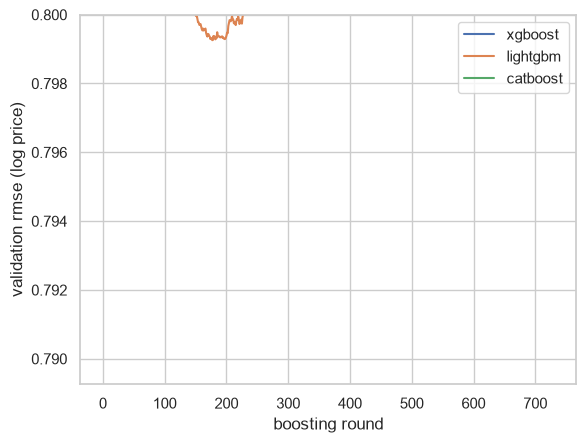

In [7]:
# how many rounds does each booster need? early stopping on a validation split
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
curves = {}

p = clone(prep_onehot).fit(X_tr)
xgb_probe = XGBRegressor(n_estimators=3000, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7,
                         early_stopping_rounds=50, tree_method='hist', random_state=SEED, n_jobs=-1)
xgb_probe.fit(p.transform(X_tr), np.log(y_tr), eval_set=[(p.transform(X_val), np.log(y_val))], verbose=False)
curves['xgboost'] = xgb_probe.evals_result()['validation_0']['rmse']

p = clone(prep_ordinal).fit(X_tr)
lgbm_probe = LGBMRegressor(n_estimators=3000, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.7, random_state=SEED, n_jobs=-1, verbose=-1)
import lightgbm as lgb
lgbm_probe.fit(p.transform(X_tr), np.log(y_tr), eval_set=[(p.transform(X_val), np.log(y_val))], eval_metric='rmse',
               categorical_feature=[0, 1, 2], callbacks=[lgb.early_stopping(50, verbose=False)])
curves['lightgbm'] = lgbm_probe.evals_result_['valid_0']['rmse']

p = clone(prep_text).fit(X_tr)
cat_probe = CatBoostRegressor(iterations=3000, learning_rate=0.08, depth=6, cat_features=cat_cols,
                              early_stopping_rounds=50, random_seed=SEED, verbose=False, thread_count=-1)
cat_probe.fit(p.transform(X_tr), np.log(y_tr), eval_set=(p.transform(X_val), np.log(y_val)))
curves['catboost'] = cat_probe.get_evals_result()['validation']['RMSE']

rounds = {'xgboost': xgb_probe.best_iteration, 'lightgbm': lgbm_probe.best_iteration_, 'catboost': cat_probe.get_best_iteration()}
print('best rounds:', rounds)
for name, c in curves.items():
    plt.plot(c, label=name)
plt.ylim(min(min(c) for c in curves.values()) - .01, 0.8)
plt.xlabel('boosting round')
plt.ylabel('validation rmse (log price)')
plt.legend()
plt.show()

## 6. tuning

randomized search, 3 fold cross validation on the training rows, scored with rmsle. the number of searches is smaller for catboost (8) because each one is slower.

In [8]:
rf_space = {
    'model__regressor__max_depth': [12, 18, 24, None],
    'model__regressor__min_samples_leaf': [3, 5, 8],
    'model__regressor__max_features': [0.33, 0.5, 0.7],
    'model__regressor__max_samples': [0.6, 0.8, 1.0],
}
rf_search = RandomizedSearchCV(make_pipeline(prep_onehot, RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1)),
                               rf_space, n_iter=12, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
rf_search.fit(X_train, y_train)
print('random forest cv rmsle:', round(-rf_search.best_score_, 4), rf_search.best_params_)

random forest cv rmsle: 0.8006 {'model__regressor__min_samples_leaf': 3, 'model__regressor__max_samples': 0.6, 'model__regressor__max_features': 0.33, 'model__regressor__max_depth': None}


In [9]:
xgb_space = {
    'model__regressor__n_estimators': [int(rounds['xgboost'] * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.05, 0.08, 0.1],
    'model__regressor__max_depth': [4, 6, 8],
    'model__regressor__min_child_weight': [1, 3, 5],
    'model__regressor__subsample': [0.7, 0.85, 1.0],
    'model__regressor__colsample_bytree': [0.5, 0.7, 0.9],
    'model__regressor__reg_lambda': [1, 5, 10],
    'model__regressor__gamma': [0, 0.1, 0.3],
}
xgb_search = RandomizedSearchCV(make_pipeline(prep_onehot, XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1)),
                                xgb_space, n_iter=20, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
xgb_search.fit(X_train, y_train)
print('xgboost cv rmsle:', round(-xgb_search.best_score_, 4), xgb_search.best_params_)

xgboost cv rmsle: 0.7951 {'model__regressor__subsample': 0.7, 'model__regressor__reg_lambda': 10, 'model__regressor__n_estimators': 388, 'model__regressor__min_child_weight': 3, 'model__regressor__max_depth': 8, 'model__regressor__learning_rate': 0.05, 'model__regressor__gamma': 0, 'model__regressor__colsample_bytree': 0.7}


In [10]:
lgbm_space = {
    'model__regressor__n_estimators': [int(rounds['lightgbm'] * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.03, 0.05, 0.08],
    'model__regressor__num_leaves': [15, 31, 63],
    'model__regressor__min_child_samples': [10, 20, 40],
    'model__regressor__subsample': [0.7, 0.85, 1.0],
    'model__regressor__colsample_bytree': [0.5, 0.7, 0.9],
    'model__regressor__reg_lambda': [0, 5, 20],
    'model__regressor__cat_smooth': [10, 30, 60],
    'model__regressor__min_data_per_group': [20, 50, 100],
}
lgbm_search = RandomizedSearchCV(
    make_pipeline(prep_ordinal, LGBMWithCategories(subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1)),
    lgbm_space, n_iter=25, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
lgbm_search.fit(X_train, y_train)
print('lightgbm cv rmsle:', round(-lgbm_search.best_score_, 4), lgbm_search.best_params_)

lightgbm cv rmsle: 0.7949 {'model__regressor__subsample': 1.0, 'model__regressor__reg_lambda': 5, 'model__regressor__num_leaves': 63, 'model__regressor__n_estimators': 142, 'model__regressor__min_data_per_group': 50, 'model__regressor__min_child_samples': 10, 'model__regressor__learning_rate': 0.05, 'model__regressor__colsample_bytree': 0.5, 'model__regressor__cat_smooth': 10}


In [11]:
cat_space = {
    'model__regressor__iterations': [int(rounds['catboost'] * f) for f in (0.6, 0.8, 1.0)],
    'model__regressor__learning_rate': [0.05, 0.08, 0.12],
    'model__regressor__depth': [4, 6, 8],
    'model__regressor__l2_leaf_reg': [1, 3, 10],
    'model__regressor__random_strength': [0.5, 1, 3],
    'model__regressor__one_hot_max_size': [2, 10],
}
cat_search = RandomizedSearchCV(
    make_pipeline(prep_text, CatBoostWithCategories(random_seed=SEED, verbose=False, thread_count=-1)),
    cat_space, n_iter=8, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
cat_search.fit(X_train, y_train)
print('catboost cv rmsle:', round(-cat_search.best_score_, 4), cat_search.best_params_)

catboost cv rmsle: 0.7998 {'model__regressor__random_strength': 0.5, 'model__regressor__one_hot_max_size': 2, 'model__regressor__learning_rate': 0.08, 'model__regressor__l2_leaf_reg': 10, 'model__regressor__iterations': 544, 'model__regressor__depth': 8}


### explainable boosting machine

the ebm (explainable boosting machine) is the model i add from outside the module, same as for houses. it is a generalized additive model fitted by boosting, one curve per feature plus a few curves for pairs, and the price is the sum of the curves. every prediction can be read off exactly. it takes the raw columns, so there is no preprocessing step, and it learns log price like the other models. same 3 fold search as the others with 6 draws. it is kept out of the `tuned` dict so the plots below still loop over the four tree models.

In [12]:
# the ebm takes the raw columns, it bins the numbers and handles categories itself
def make_ebm(**params):
    model = TransformedTargetRegressor(regressor=ExplainableBoostingRegressor(random_state=SEED, n_jobs=-1, **params),
                                       func=np.log, inverse_func=np.exp)
    return Pipeline([('model', model)])

ebm_space = {
    'model__regressor__learning_rate': [0.01, 0.02, 0.05],
    'model__regressor__max_bins': [128, 256, 512],
    'model__regressor__interactions': [0, 5, 10, 20],
    'model__regressor__outer_bags': [4, 8],
    'model__regressor__smoothing_rounds': [0, 50, 200],
}
ebm_search = RandomizedSearchCV(make_ebm(), ebm_space, n_iter=6, cv=kf, scoring=score, random_state=SEED, n_jobs=1)
ebm_search.fit(X_train, y_train)
print('ebm cv rmsle:', round(-ebm_search.best_score_, 4), ebm_search.best_params_)

ebm cv rmsle: 0.8124 {'model__regressor__smoothing_rounds': 0, 'model__regressor__outer_bags': 8, 'model__regressor__max_bins': 512, 'model__regressor__learning_rate': 0.01, 'model__regressor__interactions': 20}


## 7. results

the default parameter versions are in the table only to show what the tuning gave.

In [13]:
# the same four with default parameters, only as a reference for what the tuning gave
t = time.time()
defaults = {
    'random forest (default)': make_pipeline(prep_onehot, RandomForestRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train),
    'xgboost (default)': make_pipeline(prep_onehot, XGBRegressor(random_state=SEED, n_jobs=-1)).fit(X_train, y_train),
    'lightgbm (default)': make_pipeline(prep_ordinal, LGBMWithCategories(random_state=SEED, n_jobs=-1, verbose=-1)).fit(X_train, y_train),
    'catboost (default)': make_pipeline(prep_text, CatBoostWithCategories(random_seed=SEED, verbose=False, thread_count=-1)).fit(X_train, y_train),
}
tuned = {
    'random forest (tuned)': rf_search, 'xgboost (tuned)': xgb_search,
    'lightgbm (tuned)': lgbm_search, 'catboost (tuned)': cat_search,
}
fit_seconds = {}
for name, search in tuned.items():
    results[name] = scores(search.predict(X_test))
    fit_seconds[name] = search.refit_time_
for name, pipe in defaults.items():
    results[name] = scores(pipe.predict(X_test))

table = pd.DataFrame(results).T
table['cv rmsle'] = pd.Series({n: -s.best_score_ for n, s in tuned.items()})
table['fit seconds'] = pd.Series(fit_seconds)
table.round(3)

,rmsle,r2 (log),mae (rs k),median abs % error,cv rmsle,fit seconds
district median,1.083,0.308,730.956,58.667,NaN,NaN
location median,0.920,0.502,496.481,35.172,NaN,NaN
ridge,0.847,0.577,530.595,39.065,NaN,NaN
knn (location + size),0.883,0.541,511.129,36.615,NaN,NaN
random forest (tuned),0.778,0.644,467.162,31.480,0.801,0.506
xgboost (tuned),0.769,0.651,465.851,32.263,0.795,1.037
lightgbm (tuned),0.777,0.644,475.871,32.794,0.795,1.592
catboost (tuned),0.778,0.644,477.579,33.074,0.800,2.946
random forest (default),0.822,0.602,466.664,31.192,NaN,NaN
xgboost (default),0.787,0.635,475.240,33.320,NaN,NaN


In [14]:
# the ebm is scored next to the others but kept out of the tuned dict, which the plots below loop over
ebm_default = make_ebm().fit(X_train, y_train)
results['ebm (default)'] = scores(ebm_default.predict(X_test))
results['ebm (tuned)'] = scores(ebm_search.predict(X_test))
ebm_table = pd.DataFrame({k: results[k] for k in ['ebm (default)', 'ebm (tuned)']}).T
ebm_table['cv rmsle'] = pd.Series({'ebm (tuned)': -ebm_search.best_score_})
ebm_table.round(3)

,rmsle,r2 (log),mae (rs k),median abs % error,cv rmsle
ebm (default),0.794,0.629,490.540,34.594,NaN
ebm (tuned),0.796,0.626,498.742,35.222,0.812


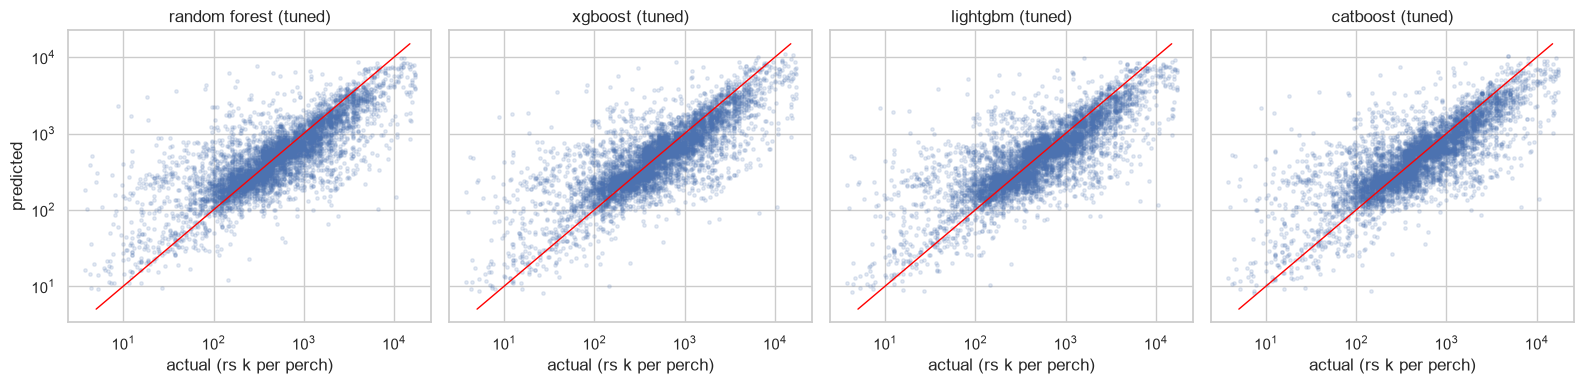

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True, sharex=True)
for a, (name, search) in zip(ax, tuned.items()):
    a.scatter(y_test / 1e3, search.predict(X_test) / 1e3, alpha=.15, s=6)
    a.plot([5, 15000], [5, 15000], color='red', linewidth=1)
    a.set_xscale('log')
    a.set_yscale('log')
    a.set_title(name)
    a.set_xlabel('actual (rs k per perch)')
ax[0].set_ylabel('predicted')
plt.tight_layout()
plt.show()

In [16]:
# where do the best models struggle
best = min(tuned, key=lambda n: results[n]['rmsle'])
pred = tuned[best].predict(X_test)
err = pd.DataFrame({'district': X_test['district'], 'size': pd.cut(X_test['land_size_perches'], [0, 6, 10, 15, 25, 1000]),
                    'pct_err': np.abs(pred - y_test) / y_test * 100})
err['district'] = err['district'].where(err['district'].map(err['district'].value_counts()) > 150, 'other districts')
print('best tuned model:', best)
print(err.groupby('district')['pct_err'].agg(['count', 'median']).round(1).sort_values('median'))
print(err.groupby('size', observed=True)['pct_err'].agg(['count', 'median']).round(1))

best tuned model: xgboost (tuned)
                 count  median
district                      
Gampaha           1228    28.3
Colombo           2794    29.0
Kalutara           623    30.5
Galle              223    33.9
Kurunegala         207    41.8
other districts   1145    42.4
Kandy              175    55.5
            count  median
size                     
(0, 6]        341    31.7
(6, 10]      2400    28.7
(10, 15]     1901    29.3
(15, 25]      685    36.1
(25, 1000]   1068    43.5


### where the best model is too high or too low

same check as for houses, on the best tuned model. the cheapest tenth of plots (median rs 53 thousand per perch) is overestimated by 118%, and the most expensive tenth (median rs 3.8 million) is underestimated by 41%. bands 3 to 6 are within about 12%. so the model pulls towards the middle here too, and much harder at the cheap end, where it is common to be more than double the real price.

the app says about 2 in 3 ads fall inside the range. on the test set 80.3% do.

In [17]:
# signed error by price band, positive means the estimate is above the real price
pct = (pred - y_test) / y_test * 100
bands = pd.DataFrame({'band': pd.qcut(y_test, 10, labels=False) + 1, 'price': y_test / 1e3, 'signed': pct, 'abs': pct.abs()})
bands.groupby('band').agg(median_price_rs_k=('price', 'median'), median_signed_pct=('signed', 'median'),
                          median_abs_pct=('abs', 'median')).round(1)

,median_price_rs_k,median_signed_pct,median_abs_pct
band,,,
1,53.1,118.2,118.2
2,145.0,38.6,42.9
3,209.0,11.5,22.1
4,314.3,0.3,25.4
5,410.0,0.5,27.5
6,550.0,1.2,22.8
7,764.0,-13.8,24.1
8,1175.0,-25.8,29.4
9,1816.7,-28.4,33.4


In [18]:
# the app says about 2 in 3 ads fall inside the range, this checks it on the test set
spread = np.exp(results[best]['rmsle'])
inside = ((y_test >= pred / spread) & (y_test <= pred * spread)).mean()
print(f'{inside:.1%} of test plots are inside the range for {best}')

80.3% of test plots are inside the range for xgboost (tuned)


## what the results say

| model | test rmsle | r2 (log) | median error | cv rmsle |
|---|---|---|---|---|
| district median | 1.083 | 0.31 | 58.7% | |
| location median | 0.920 | 0.50 | 35.2% | |
| ridge | 0.847 | 0.58 | 39.1% | |
| knn | 0.883 | 0.54 | 36.6% | |
| random forest | 0.778 | 0.64 | 31.5% | 0.8006 |
| xgboost | 0.769 | 0.65 | 32.3% | 0.7951 |
| lightgbm | 0.777 | 0.64 | 32.8% | 0.7949 |
| catboost | 0.778 | 0.64 | 33.1% | 0.7998 |

**the ebm is behind the trees but ahead of the baselines.** tuned it scores 0.796 on the test set (cv 0.812) and the default 0.794, against 0.769 to 0.778 for the four trees and 0.847 for ridge. its median error is 35.2%, about three points worse than the trees. so on land the price of an exact explanation is larger than for houses, about 0.02 to 0.03 rmsle. like for houses, the tuned ebm is not better than the default on the test set.

**the ensembles beat the simple approaches.** xgboost is 16% lower in rmsle than the location median (0.769 against 0.920) and 9% lower than ridge (0.847). ridge is better than the plain medians because it can use size and land type together with the place, but it cannot handle how they interact. a plot size matters differently in colombo than in matale.

**the four tree models are almost the same.** the test rmsle goes from 0.769 (xgboost) to 0.778 (random forest and catboost). cross validation puts lightgbm (0.7949) and xgboost (0.7951) level, so i cannot say which is better, only that all four are better than the baselines by about the same amount. so the choice between them is about other things: lightgbm and catboost use the categorical columns directly, random forest trains in half a second.

**tuning helped some models more.** the default random forest is clearly worse (0.822 against 0.778). xgboost gains 0.018 (0.787 to 0.769) and lightgbm a little (0.785 to 0.777). catboost barely moves (0.779 to 0.778), its defaults already work with location and district as categories. the default random forest has a slightly lower median error than the tuned one (31.2% against 31.5%), so the tuned one wins on the big misses, not on the typical plot.

**land is much harder than houses.** the best rmsle is 0.77 and r2 is 0.65, compared with 0.38 and 0.80 for house prices. the median miss is about 32%. the ads only give size, land type, a place and some words. nothing about road frontage, the exact street, the shape of the plot or whether the price is a real ask or just a starting number. two plots in the same town can be a factor of two apart.

**errors by group.** the median error is 28 to 31% in colombo, gampaha and kalutara, which have most of the ads. it is 42% for kurunegala and the small districts and 56% in kandy (175 test ads). by size, plots up to 15 perches are at 29 to 32%, 15 to 25 perches at 36% and over 25 perches at 44%. big plots are rare and their price per perch changes a lot, probably because big blocks are priced as one total and the per perch figure moves a lot with it.

## 8. voting and stacking

the four tree models make similar mistakes but not the same ones, so combining them might help.

- **voting:** average of the four log predictions
- **stacking (4 trees):** a linear regression with non negative weights learns from 5 fold out of fold predictions how much to trust each model
- **stacking (trees + ridge + knn):** the same, but ridge and the nearest neighbour model are added as two more inputs. this is the hybrid one, it mixes boosted trees, a linear model and a model that only knows the map

the log is taken once around the whole ensemble, so every base model learns log price.

In [19]:
def tuned_params(search):
    return {k.replace('model__regressor__', ''): v for k, v in search.best_params_.items()}

# the base models learn log price, the log is taken once around the whole ensemble
base = {
    'rf': Pipeline([('prep', prep_onehot), ('model', RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **tuned_params(rf_search)))]),
    'xgb': Pipeline([('prep', prep_onehot), ('model', XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1, **tuned_params(xgb_search)))]),
    'lgbm': Pipeline([('prep', prep_ordinal), ('model', LGBMWithCategories(subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **tuned_params(lgbm_search)))]),
    'cat': Pipeline([('prep', prep_text), ('model', CatBoostWithCategories(random_seed=SEED, verbose=False, thread_count=-1, **tuned_params(cat_search)))]),
    'ridge': Pipeline([('prep', prep_onehot), ('model', RidgeCV(alphas=np.logspace(-2, 3, 20)))]),
    'knn': Pipeline([('prep', Pipeline([('cols', knn_prep), ('scale', StandardScaler())])), ('model', KNeighborsRegressor(n_neighbors=15, weights='distance'))]),
}
trees = ['rf', 'xgb', 'lgbm', 'cat']

def log_wrap(estimator):
    return TransformedTargetRegressor(regressor=estimator, func=np.log, inverse_func=np.exp)

ensembles = {
    'voting (4 trees)': log_wrap(VotingRegressor([(n, clone(base[n])) for n in trees])),
    'stacking (4 trees)': log_wrap(StackingRegressor([(n, clone(base[n])) for n in trees], final_estimator=LinearRegression(positive=True), cv=5)),
    'stacking (trees + ridge + knn)': log_wrap(StackingRegressor([(n, clone(base[n])) for n in base], final_estimator=LinearRegression(positive=True), cv=5)),
}
for name, ens in ensembles.items():
    start = time.time()
    ens.fit(X_train, y_train)
    results[name] = scores(ens.predict(X_test))
    print(name, 'fitted in', round(time.time() - start), 'seconds')

voting (4 trees) fitted in 6 seconds


stacking (4 trees) fitted in 35 seconds


stacking (trees + ridge + knn) fitted in 36 seconds


In [20]:
ens_cv = {name: -cross_val_score(ens, X_train, y_train, cv=kf, scoring=score).mean() for name, ens in ensembles.items()}
final = pd.DataFrame(results).T.loc[['xgboost (tuned)', 'lightgbm (tuned)', 'catboost (tuned)', 'random forest (tuned)'] + list(ensembles)]
final['cv rmsle'] = pd.Series({n: -s.best_score_ for n, s in tuned.items()}).reindex(final.index)
for name, value in ens_cv.items():
    final.loc[name, 'cv rmsle'] = value
final.round(3)

,rmsle,r2 (log),mae (rs k),median abs % error,cv rmsle
xgboost (tuned),0.769,0.651,465.851,32.263,0.795
lightgbm (tuned),0.777,0.644,475.871,32.794,0.795
catboost (tuned),0.778,0.644,477.579,33.074,0.800
random forest (tuned),0.778,0.644,467.162,31.480,0.801
voting (4 trees),0.770,0.651,468.593,32.134,0.792
stacking (4 trees),0.769,0.651,464.541,31.848,0.792
stacking (trees + ridge + knn),0.768,0.652,463.339,31.819,0.792


In [21]:
# how much each base model counts in the two stacks (non negative weights on log price)
for name in ['stacking (4 trees)', 'stacking (trees + ridge + knn)']:
    inner = ensembles[name].regressor_
    weights = pd.Series(inner.final_estimator_.coef_, index=list(inner.named_estimators_), name='weight').round(3)
    print(name, '| intercept', round(float(inner.final_estimator_.intercept_), 3))
    print(weights.to_string(), '\n')

stacking (4 trees) | intercept -0.127
rf      0.313
xgb     0.370
lgbm    0.152
cat     0.174 

stacking (trees + ridge + knn) | intercept -0.148
rf       0.285
xgb      0.353
lgbm     0.132
cat      0.192
ridge    0.000
knn      0.049 



## 9. which features matter

xgboost with my tuned parameters, one group of features left out at a time, scored on the test set and with 3 fold cv. a difference of around 0.005 is noise.

In [22]:
xgb_params = tuned_params(xgb_search)

def xgb_without(drop_cols=(), label=''):
    nums = [c for c in num_cols if c not in drop_cols]
    cats = [c for c in cat_cols if c not in drop_cols]
    use_size = 'land_size_perches' not in drop_cols
    parts = ([size_log] if use_size else []) + [
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), nums),
        ('cat', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist', sparse_output=False), cats)]
    pipe = make_pipeline(ColumnTransformer(parts), XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1, **xgb_params))
    cols = [c for c in features if c not in drop_cols]
    fitted = pipe.fit(X_train[cols], y_train)
    cv = -cross_val_score(pipe, X_train[cols], y_train, cv=kf, scoring=score).mean()
    return {'what is left out': label, 'features': len(cols), 'test rmsle': scores(fitted.predict(X_test[cols]))['rmsle'], 'cv rmsle': cv}

variants = [
    ((), 'nothing'),
    (tuple(keyword_cols), 'words from the ad'),
    (('residential', 'commercial', 'agricultural'), 'land type'),
    (('latitude', 'longitude'), 'coordinates'),
    (('is_verified', 'is_member', 'membership_level'), 'seller fields'),
    (('location',), 'location (district stays)'),
    (('location', 'latitude', 'longitude'), 'location and coordinates'),
    (('land_size_perches',), 'land size'),
]
ablation = pd.DataFrame([xgb_without(drop, label) for drop, label in variants]).set_index('what is left out')
ablation.round(3)

,features,test rmsle,cv rmsle
what is left out,,,
nothing,21,0.769,0.795
words from the ad,11,0.780,0.803
land type,18,0.787,0.812
coordinates,19,0.781,0.799
seller fields,18,0.780,0.807
location (district stays),20,0.770,0.797
location and coordinates,18,0.888,0.897
land size,20,0.836,0.863


## 10. shap

shap values of the tuned xgboost on 2,000 test rows. the one hot columns of a feature are added back together.

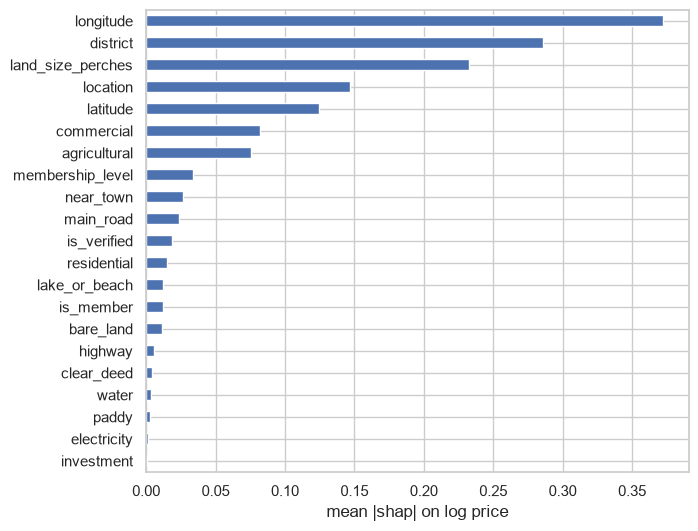

In [23]:
import shap

xgb_fitted = xgb_search.best_estimator_
prep_fit = xgb_fitted.named_steps['prep']
booster = xgb_fitted.named_steps['model'].regressor_

shap_rows = X_test.sample(2000, random_state=SEED)
Z = prep_fit.transform(shap_rows)
names = list(prep_fit.get_feature_names_out())
shap_values = shap.TreeExplainer(booster).shap_values(Z)

# one hot columns of a feature are added back together
def original(name):
    kind, rest = name.split('__', 1)
    if kind == 'cat':
        return next(c for c in cat_cols if rest.startswith(c + '_'))
    return rest

groups = pd.Series([original(n) for n in names])
importance = pd.DataFrame(np.abs(shap_values)).T.groupby(groups.values).sum().T.mean().sort_values()
importance.plot.barh(figsize=(7, 6))
plt.xlabel('mean |shap| on log price')
plt.show()

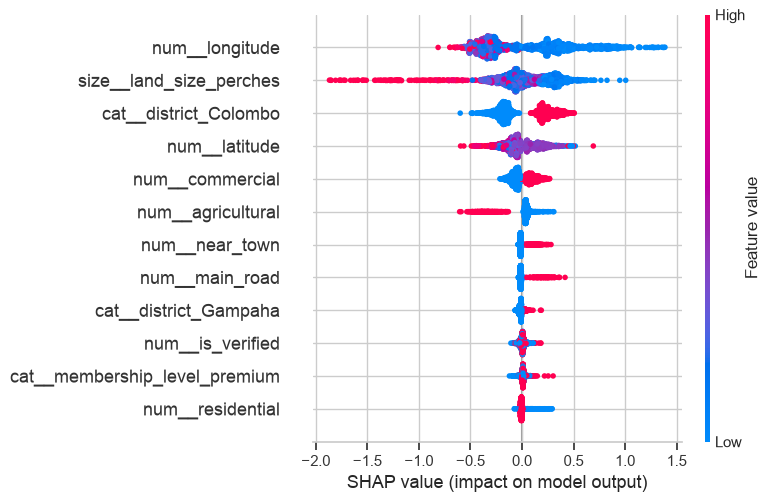

In [24]:
shap.summary_plot(shap_values, Z, feature_names=names, max_display=12, show=False)
plt.gcf().set_size_inches(8, 5)
plt.show()

In [25]:
importance.round(3).sort_values(ascending=False)

longitude            0.372
district             0.286
land_size_perches    0.233
location             0.147
latitude             0.124
commercial           0.082
agricultural         0.075
membership_level     0.034
near_town            0.027
main_road            0.024
is_verified          0.018
residential          0.015
lake_or_beach        0.012
is_member            0.012
bare_land            0.012
highway              0.005
clear_deed           0.004
water                0.003
paddy                0.003
electricity          0.001
investment           0.000
dtype: float32

### partial dependence and the shap shape of size

the average shap value of plot size in bands: +0.33 under 6 perches, +0.19 from 6 to 10, about 0 from 10 to 100 and -1.02 above 100 perches. the price per perch drops a lot for very big plots, which is what i expect, since big plots are sold as a whole and do not cost the same per perch as a small house plot.

the partial dependence on the price scale shows longitude as the sharpest one. the price per perch is highest at the west coast around longitude 79.85, which is colombo, and falls to a flat level from about 80.0. latitude only has a small bump near 6.9, also colombo. so the model learned that colombo is expensive and the rest of the island is much cheaper, which is what the data says too.

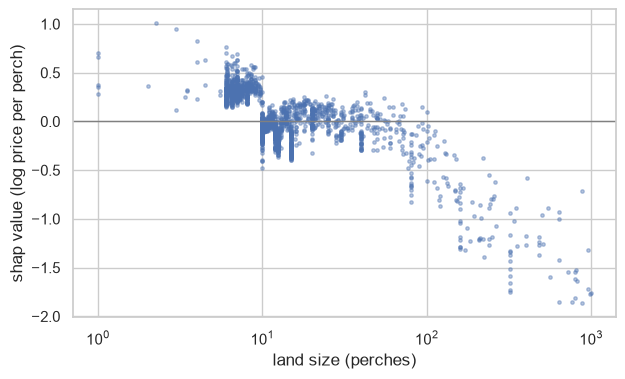

In [26]:
# shap value of land size against the real size
col = names.index('size__land_size_perches')
plt.figure(figsize=(7, 4))
plt.scatter(shap_rows['land_size_perches'], shap_values[:, col], s=6, alpha=.4)
plt.xscale('log')
plt.axhline(0, color='grey', linewidth=1)
plt.xlabel('land size (perches)')
plt.ylabel('shap value (log price per perch)')
plt.show()

In [27]:
# average shap value of land size in size bands
size_effect = pd.Series(shap_values[:, col]).groupby(pd.cut(shap_rows['land_size_perches'].values, [0, 6, 10, 15, 25, 100, 10000]))
size_effect.agg(['count', 'mean']).round(3)

,count,mean
"(0, 6]",102,0.329
"(6, 10]",778,0.186
"(10, 15]",574,-0.094
"(15, 25]",213,0.059
"(25, 100]",227,-0.093
"(100, 10000]",106,-1.017


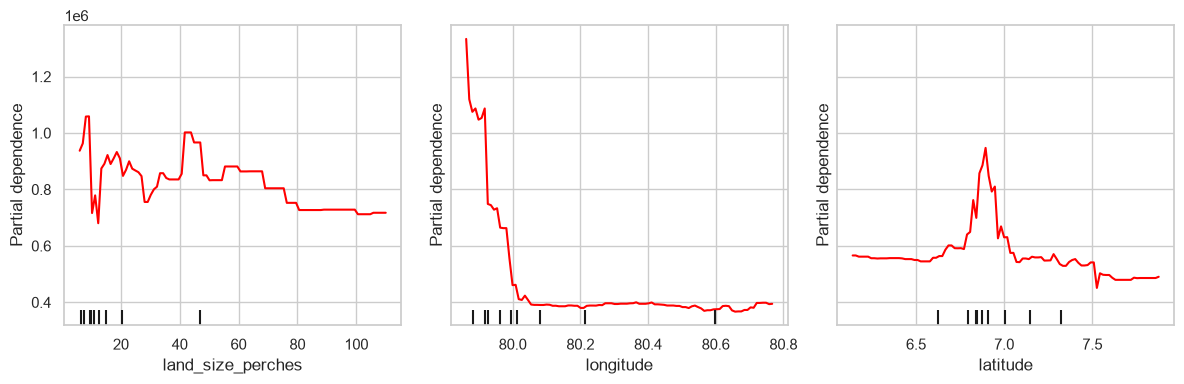

In [28]:
from sklearn.inspection import PartialDependenceDisplay

# partial dependence on the price scale, 5th to 95th percentile of each feature
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
PartialDependenceDisplay.from_estimator(xgb_fitted, shap_rows, ['land_size_perches', 'longitude', 'latitude'],
                                        kind='average', ax=ax, line_kw={'color': 'red'})
plt.tight_layout()
plt.show()

### explainable boosting machine

term importance is the mean absolute contribution to log price. location (0.532) is far ahead, then land size (0.212), district (0.201), commercial land (0.096) and agricultural land (0.088). the biggest pair is land size with longitude (0.069).

the land size curve is exact and matches the shap shape. it is above zero under about 10 perches and falls to about -1.6 around 1,000 perches, so the price per perch drops a lot for big plots. it is about +2 for one or two perches, but those are a handful of odd ads, so i do not read much into it. the curves for longitude and latitude are flat. the ebm gives the whole place effect to the location term, because the coordinates are only a function of the location, which is the same thing the leave one out table showed for xgboost.

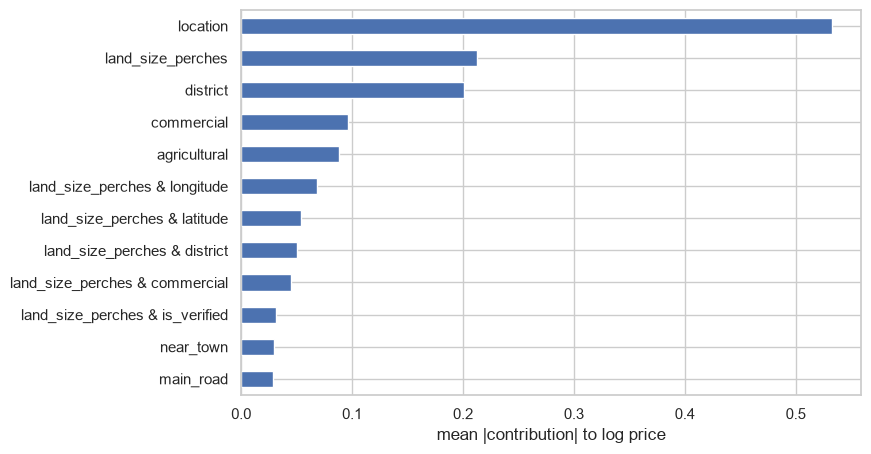

In [29]:
ebm = ebm_search.best_estimator_.named_steps['model'].regressor_
ebm_global = ebm.explain_global()

# term importance is the mean absolute contribution to log price, interactions are named with an &
term_imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values()
term_imp.tail(12).plot.barh(figsize=(8, 5))
plt.xlabel('mean |contribution| to log price')
plt.show()

In [30]:
term_imp.sort_values(ascending=False).round(3).head(12)

location                           0.532
land_size_perches                  0.212
district                           0.201
commercial                         0.096
agricultural                       0.088
land_size_perches & longitude      0.069
land_size_perches & latitude       0.054
land_size_perches & district       0.050
land_size_perches & commercial     0.045
land_size_perches & is_verified    0.031
near_town                          0.029
main_road                          0.029
dtype: float64

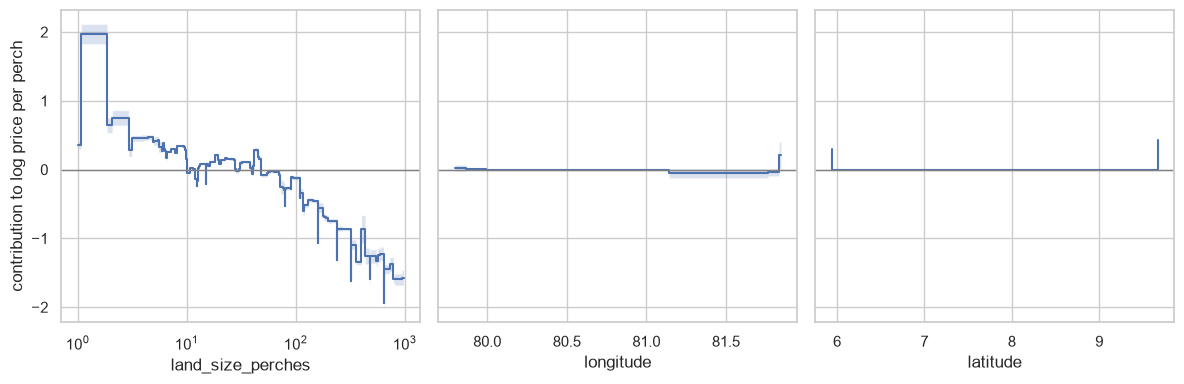

In [31]:
# the learned curve of each number: contribution to log price at each value
fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for a, name in zip(ax, ['land_size_perches', 'longitude', 'latitude']):
    d = ebm_global.data(ebm.term_names_.index(name))
    edges, scores_ = np.array(d['names'], dtype=float), np.array(d['scores'], dtype=float)
    a.step(edges[:-1], scores_, where='post')
    a.fill_between(edges[:-1], d['lower_bounds'], d['upper_bounds'], step='post', alpha=.2)
    a.axhline(0, color='grey', linewidth=1)
    a.set_xlabel(name)
    if name == 'land_size_perches':
        a.set_xscale('log')
ax[0].set_ylabel('contribution to log price per perch')
plt.tight_layout()
plt.show()

## 11. saving the model

the stack with the better cv score is refitted on all rows and saved as one pickle. the base models are inside it, so the web app can also show xgboost, lightgbm, catboost and random forest from the same file. the ebm is saved as its own pickle, fitted on all rows, and voting is the mean of the four tree predictions on the log scale. `estimators.py` has the two small wrappers the pickle needs.

In [32]:
best_stack_name = min(['stacking (4 trees)', 'stacking (trees + ridge + knn)'], key=lambda n: ens_cv[n])
print('stack used in the app:', best_stack_name)

final_model = clone(ensembles[best_stack_name]).fit(X, y)
with open('../model/land_stacking.pkl', 'wb') as f:
    pickle.dump(final_model, f)

# the ebm is a separate model that takes the same raw columns
with open('../model/land_ebm.pkl', 'wb') as f:
    pickle.dump(clone(ebm_search.best_estimator_).fit(X, y), f)

sample = {k: (None if pd.isna(v) else (v.item() if hasattr(v, 'item') else v)) for k, v in holdout[features].iloc[0].to_dict().items()}
with open('../model/land_holdout_sample.json', 'w') as f:
    json.dump({'features': sample, 'actual_price_per_perch': float(holdout['price_per_perch'].iloc[0])}, f, indent=2)

stack used in the app: stacking (trees + ridge + knn)


In [33]:
# what the web app needs
test_rmsle = {
    'random forest': results['random forest (tuned)']['rmsle'], 'xgboost': results['xgboost (tuned)']['rmsle'],
    'lightgbm': results['lightgbm (tuned)']['rmsle'], 'catboost': results['catboost (tuned)']['rmsle'],
    'voting': results['voting (4 trees)']['rmsle'], 'stacking': results[best_stack_name]['rmsle'],
    'ebm': results['ebm (tuned)']['rmsle'],
}
loc_counts = df.groupby(['district', 'location']).size()
loc_counts = loc_counts[loc_counts >= 30]
district_sizes = df['district'].value_counts()
qs = np.linspace(0, 1, 101)

meta = {
    'test_rmsle': {k: round(float(v), 4) for k, v in test_rmsle.items()},
    'results': pd.DataFrame(results).T.round(4).reset_index(names='model').to_dict('records'),
    'ablation': ablation.reset_index().round(4).to_dict('records'),
    'importance': importance.round(4).to_dict(),
    'stack_weights': {n: round(float(w), 4) for n, w in zip(final_model.regressor_.named_estimators_, final_model.regressor_.final_estimator_.coef_)},
    'keywords': keyword_cols,
    'locations': {d: sorted(loc_counts[d].index.tolist()) for d in loc_counts.index.get_level_values(0).unique()},
    'membership_levels': sorted(df['membership_level'].dropna().unique().tolist()),
    'size_range': [float(df['land_size_perches'].quantile(.01)), float(df['land_size_perches'].quantile(.99))],
    'price_quantiles': {d: df.loc[df['district'] == d, 'price_per_perch'].quantile(qs).round(0).tolist()
                        for d in district_sizes[district_sizes >= 100].index},
}
with open('../model/land_meta.json', 'w') as f:
    json.dump(meta, f)
print(meta['test_rmsle'])
print(meta['stack_weights'])

{'random forest': 0.7777, 'xgboost': 0.7693, 'lightgbm': 0.7774, 'catboost': 0.7776, 'voting': 0.7701, 'stacking': 0.7685, 'ebm': 0.7963}
{'rf': 0.1853, 'xgb': 0.3355, 'lgbm': 0.1995, 'cat': 0.2323, 'ridge': 0.0, 'knn': 0.062}


## 12. predicting the held out listing

the held out plot is 16 perches in puttalam city, residential, and the ad says near and lake. the real asking price was rs 350,000 per perch.

xgboost says 341,414 (2.5% off), the ebm 381,540 (9.0%), lightgbm 314,742 (10.1%), the stack 298,473 (14.7%), voting 294,698 (15.8%), catboost 289,441 (17.3%) and the random forest 242,502 (30.7%). the ebm is the only one above the real price, the rest are low, and all but the forest are inside the typical miss of about 32%. one plot cannot rank the models, the test set table is the fair comparison.

In [34]:
with open('../model/land_stacking.pkl', 'rb') as f:
    loaded = pickle.load(f)
with open('../model/land_holdout_sample.json') as f:
    saved = json.load(f)

point = pd.DataFrame([saved['features']])
actual = saved['actual_price_per_perch']

# every base model predicts log price, the stack and the vote are built from them
inner = loaded.regressor_
logs = {name: est.predict(point)[0] for name, est in inner.named_estimators_.items()}
preds = {'xgboost': np.exp(logs['xgb']), 'lightgbm': np.exp(logs['lgbm']), 'catboost': np.exp(logs['cat']),
         'random forest': np.exp(logs['rf']), 'voting': np.exp(np.mean([logs[n] for n in trees])),
         'stacking': loaded.predict(point)[0]}
with open('../model/land_ebm.pkl', 'rb') as f:
    preds['ebm'] = pickle.load(f).predict(point)[0]

print(point.T.to_string(header=False))
print(f'actual: rs {actual:,.0f} per perch\n')
for name, value in preds.items():
    print(f'{name:14s} rs {value:>10,.0f}   error {abs(value - actual) / actual * 100:5.1f}%')

land_size_perches           16.0
latitude                8.031599
longitude              79.830029
is_verified                    0
is_member                    1.0
residential                    1
commercial                     0
agricultural                   0
main_road                      0
highway                        0
clear_deed                     0
near_town                      1
bare_land                      0
water                          0
electricity                    0
lake_or_beach                  1
paddy                          0
investment                     0
location           Puttalam City
district                Puttalam
membership_level         premium
actual: rs 350,000 per perch

xgboost        rs    341,414   error   2.5%
lightgbm       rs    314,742   error  10.1%
catboost       rs    289,441   error  17.3%
random forest  rs    242,502   error  30.7%
voting         rs    294,698   error  15.8%
stacking       rs    298,473   error  14.7%
ebm          

## conclusion

| model | test rmsle | cv rmsle |
|---|---|---|
| stacking (trees + ridge + knn) | 0.768 | 0.792 |
| stacking (4 trees) | 0.769 | 0.792 |
| voting (4 trees) | 0.770 | 0.792 |
| xgboost | 0.769 | 0.795 |
| lightgbm | 0.777 | 0.795 |
| catboost | 0.778 | 0.800 |
| random forest | 0.778 | 0.801 |
| ridge (best simple baseline) | 0.847 | |

**ensembles help, but only a little.** the best stack is 0.768 on the test set against 0.769 for xgboost alone, and 0.792 against 0.795 in cv. that is smaller than the 0.005 noise i saw in the leave one out table, so i would not claim it is better. what the stack does give is a slightly lower cv score for all three combinations, so it is a bit steadier. xgboost alone is almost as good and its file is a small fraction of the 54 MB stack.

**what the stack learned.** xgboost gets the biggest weight (0.34), then catboost (0.23), lightgbm (0.20) and the random forest (0.19). knn on the map gets a small weight (0.06) and ridge gets zero, so after the trees a linear model adds nothing and the map neighbours add a little.

**why boosted trees for land.** price per perch depends on place and size together, and the effect of size is different in every area. ridge cannot do that (0.847), the trees can (0.77). lightgbm and catboost read location and district as categories without one hot encoding but that did not make them better than xgboost here, the dataset is too small and noisy for it to matter.

**what the features do.** leaving out location and coordinates together costs the most (0.769 to 0.888), but either one alone is enough, since the coordinates are just the location in another form (without location 0.770, without coordinates 0.781). land size is next (0.836 without it). land type adds 0.018, words from the ad 0.011 and seller fields 0.011. shap says the same: longitude (0.37), district (0.29), size (0.23), location (0.15) and latitude (0.12) are far ahead, then commercial and agricultural land (0.08 each). each ad word is small, near (0.027) and main road (0.024) are the biggest. longitude ranks above latitude probably because it separates the western coast around colombo from the rest of the island, not because east to west matters more.

**limits.**
- the median miss is about 32%. the ads say nothing about road frontage, the street or the shape of the plot
- 70% of land ads were reposts and i kept one of each. one seller can still have several similar plots, one in train and one in test. the seller id is not in the cleaned file so i could not check this, the real error on a new seller may be higher
- these are asking prices from 7 months of ads, and kandy and the smaller districts have few ads